# Bài 1 · Tiền xử lý văn bản tiếng Việt

**Thời lượng gợi ý:** 120 phút · **Cần:** Bài 0 · **Không cần GPU**

## Mục tiêu

1. Chuẩn hóa Unicode (NFC) và làm sạch văn bản có kiểm soát bằng biểu thức chính quy.
2. Đo được **cái giá** của việc bỏ dấu và của việc xóa từ dừng/phủ định.
3. Tách câu và tách từ; phân biệt *âm tiết*, *từ*, *subword* và biết khi nào cần cái nào.
4. Dựng một hàm tiền xử lý có thể cấu hình và dùng lại ở các bài sau.

> Tiền xử lý **không có đáp án đúng chung**. Mỗi bước là một quyết định mô hình hóa: nó bỏ đi thông tin, và thông tin đó có thể chính là thứ bạn cần. Đừng bao giờ sao chép một danh sách bước "chuẩn" mà không đo.

In [1]:
import sys, pathlib

ROOT = pathlib.Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings("ignore")

import re
import unicodedata
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from nlpvi import (LABELS, get_segmenter, load_reviews, normalize, segment, set_seed,
                   split_sentences, strip_accents, tokenize_surface)

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
set_seed(42)
df = load_reviews()
train = df[df["split"] == "train"].reset_index(drop=True)
print(len(train), "mẫu train")

1262 mẫu train


## 1. Unicode: luôn bắt đầu bằng NFC

Python so sánh chuỗi theo *điểm mã (code point)*, không theo hình dạng. Một chữ như "ế" có thể được viết bằng 1 hoặc 3 điểm mã. Văn bản đến từ nhiều nguồn (Word, web, điện thoại) thường trộn cả hai dạng. Nếu không chuẩn hóa, từ điển sẽ coi "việt" (NFC) và "việt" (NFD) là **hai từ khác nhau**.

In [2]:
w_nfc = "tiếng việt"
w_nfd = unicodedata.normalize("NFD", w_nfc)

print("Hiển thị:", w_nfc, "|", w_nfd)
print("Độ dài  :", len(w_nfc), "vs", len(w_nfd))
print("Bằng nhau?", w_nfc == w_nfd)
print("Các điểm mã của 'ế' dạng NFD:", [f"U+{ord(c):04X} {unicodedata.name(c)}" for c in unicodedata.normalize("NFD", "ế")])

vocab = Counter([w_nfc, w_nfd, w_nfc])
print("\nTừ điển KHÔNG chuẩn hóa:", dict(vocab))
vocab = Counter(unicodedata.normalize("NFC", w) for w in [w_nfc, w_nfd, w_nfc])
print("Từ điển ĐÃ chuẩn hóa NFC:", dict(vocab))

Hiển thị: tiếng việt | tiếng việt
Độ dài  : 10 vs 14
Bằng nhau? False
Các điểm mã của 'ế' dạng NFD: ['U+0065 LATIN SMALL LETTER E', 'U+0302 COMBINING CIRCUMFLEX ACCENT', 'U+0301 COMBINING ACUTE ACCENT']

Từ điển KHÔNG chuẩn hóa: {'tiếng việt': 2, 'tiếng việt': 1}
Từ điển ĐÃ chuẩn hóa NFC: {'tiếng việt': 3}


**NFC hay NFKC?** NFKC còn "hạ" các ký tự tương thích (ví dụ `①` → `1`, ký tự toàn chiều rộng → thường) nên mạnh tay hơn. Với tiếng Việt, NFC là lựa chọn an toàn; chỉ dùng NFKC khi dữ liệu có nhiều ký tự lạ và bạn đã kiểm tra kết quả.

## 2. Làm sạch bằng biểu thức chính quy

Mục tiêu là *giảm nhiễu mà không giết tín hiệu*. Ta thử từng bước và nhìn kết quả trước/sau.

In [3]:
mau = [
    "Sp ngonnnnn quááááá!!! Xem thêm tại https://shop.vn/abc nhé @shop_abc",
    "Liên hệ 0912 345 678 hoặc mail abc@gmail.com để biết thêm",
    "KHÔNG hài lòng.... giao hàng trễ!!!???",
    "Mình dc tặng 1 cái, ko dùng thử nên chưa biết 😍👍",
]

steps = {
    "URL → ' URL '":        lambda t: re.sub(r"https?://\S+|www\.\S+", " URL ", t),
    "@tên → ' USER '":      lambda t: re.sub(r"(?<!\w)@\w+", " USER ", t),
    "SĐT → ' SDT '":        lambda t: re.sub(r"(?<!\d)(?:\+?84|0)(?:[\s.\-]?\d){9}(?!\d)", " SDT ", t),
    "kéo dài chữ cái":      lambda t: re.sub(r"([^\W\d_])\1{2,}", r"\1", t),
    "lặp dấu câu":          lambda t: re.sub(r"([!?.])\1+", r"\1", t),
    "hạ chữ thường":        lambda t: t.lower(),
    "gộp khoảng trắng":     lambda t: re.sub(r"\s+", " ", t).strip(),
}

for t in mau[:3]:
    print("GỐC :", t)
    for ten, f in steps.items():
        t2 = f(t)
        if t2 != t:
            print(f"  {ten:18s}→ {t2}")
            t = t2
    print()

GỐC : Sp ngonnnnn quááááá!!! Xem thêm tại https://shop.vn/abc nhé @shop_abc
  URL → ' URL '     → Sp ngonnnnn quááááá!!! Xem thêm tại  URL  nhé @shop_abc
  @tên → ' USER '   → Sp ngonnnnn quááááá!!! Xem thêm tại  URL  nhé  USER 
  kéo dài chữ cái   → Sp ngon quá!!! Xem thêm tại  URL  nhé  USER 
  lặp dấu câu       → Sp ngon quá! Xem thêm tại  URL  nhé  USER 
  hạ chữ thường     → sp ngon quá! xem thêm tại  url  nhé  user 
  gộp khoảng trắng  → sp ngon quá! xem thêm tại url nhé user

GỐC : Liên hệ 0912 345 678 hoặc mail abc@gmail.com để biết thêm
  SĐT → ' SDT '     → Liên hệ  SDT  hoặc mail abc@gmail.com để biết thêm
  hạ chữ thường     → liên hệ  sdt  hoặc mail abc@gmail.com để biết thêm
  gộp khoảng trắng  → liên hệ sdt hoặc mail abc@gmail.com để biết thêm

GỐC : KHÔNG hài lòng.... giao hàng trễ!!!???
  lặp dấu câu       → KHÔNG hài lòng. giao hàng trễ!?
  hạ chữ thường     → không hài lòng. giao hàng trễ!?



**Hai cạm bẫy thường gặp**

- `(\w)\1{2,}` gộp "quááááá" thành "quá" (đúng ý) nhưng `\w` cũng khớp chữ số, nên "1000" bị biến thành "10" — **số liệu bị hỏng một cách âm thầm**. Cách sửa là chỉ áp dụng cho chữ cái: `([^\W\d_])\1{2,}`. Đây là lỗi mà chính phiên bản đầu của gói `nlpvi` đã mắc; bài học: luôn in vài ví dụ trước/sau.
- Việc bạn mất đi **mức độ nhấn mạnh** ("ngonnnnn" mạnh hơn "ngon") là thật. Nếu độ mạnh cảm xúc quan trọng, hãy giữ một đặc trưng riêng ("có kéo dài chữ").

In [4]:
# Cạm bẫy: gộp ký tự lặp cũng phá số liệu
print(re.sub(r"(\w)\1{2,}", r"\1", "Giá 1000 đồng, ngonnnn"), "  ← SAI: 1000 thành 10")
print(re.sub(r"([^\W\d_])\1{2,}", r"\1", "Giá 1000 đồng, ngonnnn"), "  ← đúng: chỉ gộp chữ cái")

Giá 10 đồng, ngon   ← SAI: 1000 thành 10
Giá 1000 đồng, ngon   ← đúng: chỉ gộp chữ cái


## 3. Teencode và viết tắt

Bình luận mạng xã hội đầy viết tắt: `ko`, `k`, `dc`, `sp`, `nv`, `mn`... Có hai hướng: ánh xạ bằng từ điển (đơn giản, kiểm soát được) hoặc để mô hình tự học (cần nhiều dữ liệu). Từ điển có điểm yếu: **nhập nhằng**.

In [5]:
from nlpvi import TEENCODE

print("Từ điển teencode đang dùng:", TEENCODE)

# "k" có thể là 'không' hay 'nghìn'? Chỉ đúng nếu ta biết ngữ cảnh.
for t in ["k thích sp này", "sp giá 50k thôi", "sp giá 50 k thôi"]:
    print(f"{t!r:26} → {normalize(t)!r}")

Từ điển teencode đang dùng: {'ko': 'không', 'k': 'không', 'hok': 'không', 'hông': 'không', 'dc': 'được', 'đc': 'được', 'sp': 'sản phẩm', 'nv': 'nhân viên', 'mik': 'mình', 'mn': 'mọi người', 'ok': 'ổn', 'oke': 'ổn', 'thanks': 'cảm ơn', 'cám': 'cảm'}
'k thích sp này'           → 'không thích sản phẩm này'
'sp giá 50k thôi'          → 'sản phẩm giá 50k thôi'
'sp giá 50 k thôi'         → 'sản phẩm giá 50 không thôi'


Hàm `normalize` chỉ ánh xạ *cả token*, nên "50k" an toàn, nhưng "50 k" (viết rời) bị đổi thành "50 không" — một lỗi thật. Cách xử lý: thêm quy tắc đứng trước (`\d+\s*k` là tiền) hoặc chỉ ánh xạ `k` khi nó không đi sau chữ số. **Luôn kiểm tra trên mẫu ngẫu nhiên từ dữ liệu** thay vì tin vào từ điển.

## 4. Bỏ dấu: tiết kiệm đến đâu, mất đến đâu?

Nhiều người nhập tiếng Việt không dấu ("giao hang nhanh"). Một hướng là **bỏ dấu toàn bộ** để mọi biến thể về một dạng. Hãy đo xem ta mất gì: có bao nhiêu từ khác nhau bị dồn thành cùng một chuỗi?

In [6]:
tu = Counter()
for t in train["text"]:
    for w in tokenize_surface(normalize(t, expand_teencode=False)):
        if w.isalpha():
            tu[w] += 1

# Chỉ xét các từ CÓ dấu (bỏ qua biến thể vốn đã viết không dấu trong dữ liệu nhiễu)
co_dau = [w for w in tu if strip_accents(w) != w]
nhom = {}
for w in co_dau:
    nhom.setdefault(strip_accents(w), set()).add(w)

va_cham = {k: v for k, v in nhom.items() if len(v) > 1}
bi_dan = sum(len(v) for v in va_cham.values())
print(f"Số từ có dấu khác nhau          : {len(co_dau)}")
print(f"Số dạng khác nhau sau khi bỏ dấu: {len(nhom)}")
print(f"Số nhóm bị dồn (≥2 từ có dấu)   : {len(va_cham)}")
print(f"Số từ có dấu bị mất phân biệt   : {bi_dan}/{len(co_dau)} = {bi_dan/len(co_dau):.0%}")

top = sorted(va_cham.items(), key=lambda kv: -sum(tu[w] for w in kv[1]))[:8]
for k, v in top:
    print(f"  {k!r:8} ← {sorted(v)}")

print("\nLưu ý: dữ liệu còn chứa sẵn biến thể không dấu, nên 'khong' và 'không' cùng tồn tại:",
      "khong" in tu and "không" in tu)

Số từ có dấu khác nhau          : 331
Số dạng khác nhau sau khi bỏ dấu: 269
Số nhóm bị dồn (≥2 từ có dấu)   : 52
Số từ có dấu bị mất phân biệt   : 114/331 = 34%
  'dung'   ← ['dùng', 'dụng', 'đúng']
  'thu'    ← ['thủ', 'thứ', 'thử']
  'chat'   ← ['chát', 'chất', 'chật']
  'ky'     ← ['ký', 'kỳ']
  'tinh'   ← ['tình', 'tính']
  'do'     ← ['dở', 'độ']
  'hoi'    ← ['hơi', 'hời']
  'ung'    ← ['ủng', 'ứng']

Lưu ý: dữ liệu còn chứa sẵn biến thể không dấu, nên 'khong' và 'không' cùng tồn tại: True


Một phần đáng kể các từ có dấu bị mất phân biệt (xem con số ở trên) — chưa kể các ca nặng hơn như "ma/má/mà/mả/mã/mạ" trong kho văn bản lớn. Quy tắc thực dụng:

- **Mặc định giữ dấu**: nó mang nghĩa, và các mô hình tiền huấn luyện như PhoBERT được học trên chữ có dấu.
- Nhưng đừng coi đó là chân lý. Nếu dữ liệu của bạn lẫn nhiều dòng không dấu và từ vựng hẹp, bỏ dấu có thể *không hại* — thậm chí còn có lợi vì gộp được các biến thể. Ở Bài 3 (mục 11) ta sẽ đo và thấy đúng như vậy trên bộ dữ liệu này.
- Cách thường tốt hơn cả hai là *tăng cường dữ liệu*: giữ dấu và **thêm bản sao không dấu** của mẫu huấn luyện, thay vì xóa dấu ở mọi nơi.

## 5. Tách câu

Quy tắc đơn giản: cắt sau `. ! ? …` khi theo sau là khoảng trắng rồi một chữ hoặc số. Nó chạy tốt với văn bản sạch, nhưng sẽ sai với viết tắt (số thập phân như "3.5" thì an toàn vì sau dấu chấm không có khoảng trắng).

> **Bài học regex (lỗi có thật của giáo trình này).** Phiên bản đầu của hàm chỉ cắt khi chữ kế tiếp *viết hoa*, dùng lớp ký tự `[A-ZÀ-Ỵ]`. Nhưng dải Unicode `À–Ỵ` chứa **cả chữ thường có dấu** (như `đ`, `ứ`, `ổ`), nên hàm cắt trước `đóng gói` mà *không* cắt trước `giao hàng`: văn bản đã hạ chữ thường bị tách câu thất thường — và các bài n-gram/embedding (Bài 4–5, 8) vốn hạ chữ thường *trước khi* tách câu nên đã bị ảnh hưởng. Bản hiện tại không dựa vào chữ hoa. Hai bài học: (1) **đừng dùng dải ký tự Unicode để bắt "chữ hoa"** — dùng `str.isupper()`; (2) luôn kiểm thử bộ tách câu trên văn bản *đã chuẩn hóa* chứ không chỉ văn bản sạch, và giữ một **kiểm thử hồi quy** (xem `tests/test_nlpvi.py`).

In [7]:
vd = "Sản phẩm tốt. Giao hàng nhanh! Tôi rất hài lòng. Giá chỉ 3.5 triệu thôi."
print(split_sentences(vd))

vd2 = "Cửa hàng ở TP. Hồ Chí Minh, mở cửa lúc 8 giờ. Ông A. Nguyễn đến mua hàng."
print(split_sentences(vd2))

['Sản phẩm tốt.', 'Giao hàng nhanh!', 'Tôi rất hài lòng.', 'Giá chỉ 3.5 triệu thôi.']
['Cửa hàng ở TP.', 'Hồ Chí Minh, mở cửa lúc 8 giờ.', 'Ông A.', 'Nguyễn đến mua hàng.']


Câu thứ hai bị cắt sai ở "TP." và "A.". Cách khắc phục: danh sách viết tắt (`TP.`, `PGS.`, `TS.`...), hoặc dùng bộ tách câu có huấn luyện (ví dụ `underthesea.sent_tokenize`). Nguyên tắc: **kiểm tra bộ tách câu trên chính dữ liệu của bạn**, đừng giả định nó đúng.

## 6. Tách từ: từ âm tiết đến từ

Có ba "đơn vị" khác nhau mà người mới hay nhầm:

| Đơn vị | Ví dụ với "học sinh giỏi" | Dùng khi |
|---|---|---|
| Âm tiết (tách khoảng trắng) | `học` · `sinh` · `giỏi` | baseline nhanh, mô hình ký tự/subword |
| **Từ** (có ghép từ) | `học_sinh` · `giỏi` | PhoBERT, nhiều công cụ NLP tiếng Việt, từ điển |
| Subword (BPE/WordPiece) | `học` · `sinh` · `gi@@` · `ỏi` | mô hình đa ngôn ngữ, Transformer |

PhoBERT được tiền huấn luyện trên văn bản **đã tách từ**, nên bạn phải tách từ trước khi đưa vào (Bài 10).

**Cách ta làm ở đây.** Thuật toán *khớp tối đa từ trái sang phải* (forward maximum matching): tại mỗi vị trí, thử ghép 4, 3, rồi 2 âm tiết; nếu cụm đó có trong từ điển thì lấy. Từ điển lấy từ các từ ghép trong từ vựng của PhoBERT (`data/tu_ghep_phobert.txt`, ~22 nghìn từ). Hãy đọc mã nguồn `nlpvi/segment.py` — chỉ khoảng 20 dòng.

In [8]:
cau = [
    "Học sinh đang học xử lý ngôn ngữ tự nhiên .",
    "Chất lượng sản phẩm rất tốt , giao hàng nhanh .",
    "Nhân viên tư vấn nhiệt tình ở Hà Nội .",
    "Khóa học này có nội dung bổ ích và tài liệu đầy đủ .",
]
for c in cau:
    print("Âm tiết:", c)
    print("Từ     :", segment(c))
    print()

Âm tiết: Học sinh đang học xử lý ngôn ngữ tự nhiên .
Từ     : Học_sinh đang học xử_lý ngôn_ngữ tự_nhiên .

Âm tiết: Chất lượng sản phẩm rất tốt , giao hàng nhanh .
Từ     : Chất_lượng sản_phẩm rất tốt , giao hàng nhanh .

Âm tiết: Nhân viên tư vấn nhiệt tình ở Hà Nội .
Từ     : Nhân_viên tư_vấn nhiệt_tình ở Hà_Nội .

Âm tiết: Khóa học này có nội dung bổ ích và tài liệu đầy đủ .
Từ     : Khóa học này có nội_dung bổ_ích và tài_liệu đầy_đủ .



### So sánh với bộ tách từ có huấn luyện

Underthesea dùng mô hình học máy huấn luyện trên dữ liệu đã gán nhãn, nên về nguyên tắc nhìn được ngữ cảnh để xử lý nhập nhằng — nhưng nó cũng có lỗi riêng. Hàm dưới đây thử dùng nó, và **lùi về từ điển nếu không chạy được**, để giáo trình chạy mọi nơi. Đừng coi bên nào là "đáp án đúng": hãy nhìn các chỗ khác nhau.

In [9]:
seg_dict = get_segmenter("dictionary")
seg_uts = get_segmenter("underthesea")      # tự in cảnh báo và lùi về từ điển nếu lỗi

khac = 0
tong = 0
for c in train["text"].head(300):
    a, b = seg_dict(c), seg_uts(c)
    tong += 1
    if a.replace(" .", ".") != b.replace(" .", "."):
        khac += 1
        if khac <= 4:
            print("TỪ ĐIỂN  :", a)
            print("UNDERTHESEA:", b)
            print()
print(f"Khác nhau ở {khac}/{tong} câu (chỉ có nghĩa khi Underthesea chạy được; nếu nó bị chặn thì hai bên giống hệt).")

TỪ ĐIỂN  : tuy giá chát nhưng không_gian sạch_sẽ . cho 5 sao .
UNDERTHESEA: tuy giá_chát nhưng không_gian sạch_sẽ . cho 5 sao .

TỪ ĐIỂN  : Khóa học gồm mười_hai buổi . Chưa biết có dùng lại không !
UNDERTHESEA: Khóa học gồm mười hai buổi . Chưa biết có dùng lại không !

TỪ ĐIỂN  : dung_lượng khoảng 80 mb . thông_báo khá rõ_ràng . cho 5 sao .
UNDERTHESEA: dung lượng khoảng 80 mb . thông_báo khá rõ_ràng . cho 5 sao .

TỪ ĐIỂN  : Thời_gian xử_lý khoảng hai ngày , nhân_viên hướng_dẫn theo đúng quy_trình . Mình ghi_nhận xét vậy thôi .
UNDERTHESEA: Thời_gian xử_lý khoảng hai ngày , nhân_viên hướng_dẫn theo đúng quy_trình . Mình ghi_nhận_xét vậy thôi .



Khác nhau ở 60/300 câu (chỉ có nghĩa khi Underthesea chạy được; nếu nó bị chặn thì hai bên giống hệt).


### Đơn vị nào cho từ điển nhỏ hơn và ít từ lạ hơn?

Hai tiêu chí quan trọng khi chọn đơn vị: kích thước từ điển và **tỉ lệ OOV** (out-of-vocabulary: từ ở tập valid không có trong từ điển học từ train).

In [10]:
valid = df[df["split"] == "valid"].reset_index(drop=True)

def lay_token(texts, mode):
    out = []
    for t in texts:
        t = normalize(t, emoji="drop")
        toks = tokenize_surface(t) if mode == "âm tiết" else tokenize_surface_word(t)
        out.append([w for w in toks if any(ch.isalnum() for ch in w)])
    return out

def tokenize_surface_word(t):
    return segment(t).split()

rows = []
for mode in ["âm tiết", "từ ghép"]:
    tr = lay_token(train["text"], mode)
    va = lay_token(valid["text"], mode)
    v = set(w for s in tr for w in s)
    tot = sum(len(s) for s in va)
    oov = sum(w not in v for s in va for w in s)
    rows.append({"đơn vị": mode, "kích thước từ điển": len(v), "token trong valid": tot, "tỉ lệ OOV": f"{oov/tot:.2%}"})
pd.DataFrame(rows)

,đơn vị,kích thước từ điển,token trong valid,tỉ lệ OOV
0,âm tiết,570,3158,0.44%
1,từ ghép,526,2497,0.60%


Trên kho nhỏ và đồng nhất này, từ điển *từ ghép* nhỏ hơn một chút (nhiều âm tiết chỉ xuất hiện bên trong từ ghép) nhưng tỉ lệ OOV lại cao hơn một chút: một từ ghép lạ thì cả từ là OOV, còn tách âm tiết thì từng âm tiết vẫn quen thuộc. Trên kho văn bản lớn và đa dạng, từ điển *từ* thường lớn hơn nhiều so với từ điển âm tiết (vốn chỉ vài nghìn mục). Subword (Bài 9) giải quyết đúng vấn đề OOV: từ lạ luôn tách được thành mảnh nhỏ đã biết.

## 7. Từ dừng, phủ định và định luật Zipf

**Từ dừng (stop words)** là từ rất phổ biến ("là", "và", "của"...). Xóa chúng làm vector nhỏ gọn hơn, nhưng cũng nguy hiểm: trong tiếng Việt, những từ như **"không", "chưa", "chẳng", "hơi", "rất"** là từ dừng *theo tần suất* nhưng lại mang nghĩa cảm xúc.

Trước hết xem phân phối tần suất. Văn bản tự nhiên tuân theo **định luật Zipf**: tần suất của từ hạng *r* xấp xỉ tỉ lệ nghịch với *r* (một đường thẳng trên đồ thị log-log); vài từ chiếm phần lớn số lần xuất hiện, còn đa số từ chỉ xuất hiện rất ít. Dữ liệu tổng hợp của ta có từ vựng nhỏ và khuôn câu lặp lại nên chỉ *gần đúng* Zipf; trên văn bản thật đường này thẳng hơn nhiều.

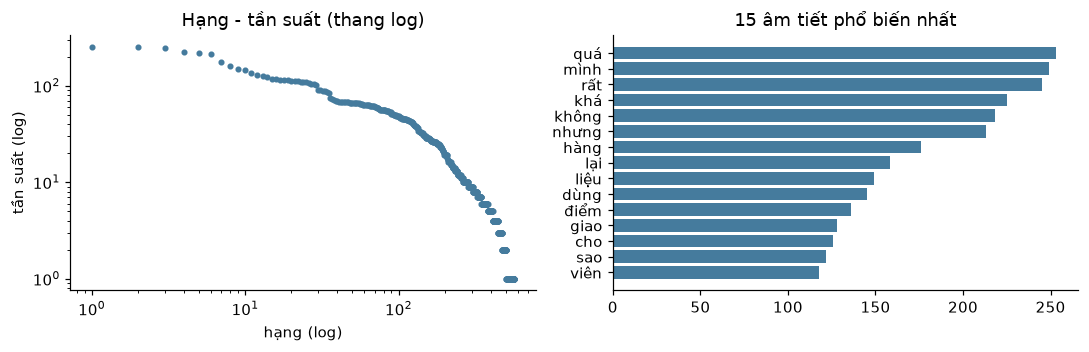

570 âm tiết khác nhau; 67 âm tiết chỉ xuất hiện đúng 1 lần (12%)
Top 10 âm tiết chiếm 14% tổng số token


In [11]:
freq = Counter(w for s in lay_token(train["text"], "âm tiết") for w in s)
vals = np.array(sorted(freq.values(), reverse=True))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.3))
ax[0].loglog(np.arange(1, len(vals) + 1), vals, ".", color="#457b9d")
ax[0].set_xlabel("hạng (log)"); ax[0].set_ylabel("tần suất (log)"); ax[0].set_title("Hạng - tần suất (thang log)")
top15 = freq.most_common(15)
ax[1].barh([w for w, _ in top15][::-1], [c for _, c in top15][::-1], color="#457b9d")
ax[1].set_title("15 âm tiết phổ biến nhất")
plt.tight_layout(); plt.show()

print(f"{len(vals)} âm tiết khác nhau; {(vals == 1).sum()} âm tiết chỉ xuất hiện đúng 1 lần ({(vals == 1).mean():.0%})")
print(f"Top 10 âm tiết chiếm {vals[:10].sum() / vals.sum():.0%} tổng số token")

### Phủ định mang tín hiệu: đo bằng số liệu

Ta so sánh tần suất xuất hiện *mỗi 1000 token* của vài từ dừng giữa ba nhãn. Nếu một từ "dừng" có tần suất khác hẳn giữa các nhãn, xóa nó là mất tín hiệu.

In [12]:
tu_xet = ["không", "chưa", "chẳng", "hơi", "quá", "rất", "nhưng"]
rows = {}
for lab in LABELS:
    toks = [w for s in lay_token(train.loc[train["label"] == lab, "text"], "âm tiết") for w in s]
    c = Counter(toks)
    rows[lab] = {w: 1000 * c[w] / len(toks) for w in tu_xet}
tbl = pd.DataFrame(rows).round(1)
tbl.index.name = "mỗi 1000 token"
tbl

,tích cực,tiêu cực,trung tính
mỗi 1000 token,,,
không,10.7,24.0,11.1
chưa,0.6,2.4,9.4
chẳng,4.5,2.8,0.0
hơi,2.2,17.1,3.7
quá,18.1,23.8,7.8
rất,22.4,16.7,7.8
nhưng,17.9,20.2,0.7


Các từ "dừng" này phân bố rất khác nhau giữa các nhãn: "không" nhiều gấp khoảng hai lần ở nhãn *tiêu cực*, "chưa" nhiều nhất ở nhãn *trung tính* ("chưa dùng nên chưa đánh giá"), còn "nhưng" gần như vắng mặt ở nhãn *trung tính*. Chiều của tín hiệu còn **đảo theo ngữ cảnh**: "không tốt" tiêu cực, "không tệ" tích cực. Xóa các từ này thì "giá không rẻ" thành "giá rẻ" — đảo ngược nghĩa. **Không xóa từ phủ định.**

## 8. Gói lại thành một hàm tiền xử lý

Từ các quyết định ở trên, bản hoàn chỉnh nằm trong `nlpvi/text.py` (`normalize`). Nó:

- chuẩn hóa NFC;
- che URL, tên người dùng, số điện thoại, email bằng token chung (danh tính cụ thể không có ích và còn là dữ liệu cá nhân);
- gộp chữ/dấu câu bị kéo dài;
- mở rộng teencode (có thể tắt);
- **giữ** dấu tiếng Việt, từ phủ định, dấu `!` `?` và emoji.

In [13]:
import inspect
import nlpvi.text as t
print(inspect.signature(t.normalize))

tests = [
    "Sp ngonnnnn quááááá!!! https://shop.vn/abc @shop_abc 😍",
    "Mình KHÔNG hài lòng.... liên hệ 0912 345 678",
    "Giao hàng nhanh, đóng gói ok. Gửi mail abc@gmail.com nhé",
]
for x in tests:
    print(f"{x!r}\n  → {normalize(x)!r}")

(text: str, *, lower=True, mask_url=True, mask_user=True, mask_phone=True, mask_email=True, squeeze_repeats=True, expand_teencode=True, emoji='keep') -> str
'Sp ngonnnnn quááááá!!! https://shop.vn/abc @shop_abc 😍'
  → 'sản phẩm ngon quá! url user 😍'
'Mình KHÔNG hài lòng.... liên hệ 0912 345 678'
  → 'mình không hài lòng. liên hệ sdt'
'Giao hàng nhanh, đóng gói ok. Gửi mail abc@gmail.com nhé'
  → 'giao hàng nhanh, đóng gói ok. gửi mail email nhé'


## 9. Tổng kết

| Quyết định | Khuyến nghị cho phân loại thông thường |
|---|---|
| Unicode | Luôn NFC |
| Chữ hoa/thường | Hạ chữ thường cho mô hình cổ điển; giữ nguyên với mô hình phân biệt hoa/thường (BERT có "cased") |
| Dấu tiếng Việt | Mặc định giữ; **đo** trước khi bỏ (xem Bài 3, mục 11) |
| Từ phủ định, `!`, `?`, emoji | **Giữ** |
| URL, SĐT, email, @user | Thay bằng token loại |
| Viết tắt/teencode | Ánh xạ có kiểm tra; cẩn thận nhập nhằng |
| Từ dừng | Chỉ bỏ khi đã đo có lợi; không bỏ từ phủ định |
| Đơn vị | Âm tiết cho baseline; từ ghép cho PhoBERT; subword cho Transformer |

## Bài tập

1. **(Dễ)** Thêm bước thay chữ số bằng token `NUM` (nhưng giữ nguyên "5 sao"). Viết regex, thử trên 5 câu.
2. **(Dễ)** Thêm ba viết tắt khác vào `TEENCODE` mà bạn thường gặp (ví dụ `bt`, `vs`, `trc`). Cho một ví dụ mà ánh xạ của bạn gây sai.
3. **(Vừa)** Sửa `split_sentences` để không cắt sau `TP.`, `TS.`, `PGS.`, `GS.`. Kiểm tra bằng `vd2`.
4. **(Vừa)** Tìm 10 cặp từ ghép dài 3 âm tiết mà bộ tách từ điển ghép sai hoặc bỏ sót trong `train`. Đề xuất cách sửa.
5. **(Khó)** Viết hàm `tach_tu_chinh_xac(text, từ_điển_thêm)` cho phép người dùng bổ sung từ chuyên ngành (ví dụ "chăm sóc khách hàng") và đảm bảo nó được ưu tiên hơn từ điển mặc định.

<details>
<summary><b>Gợi ý đáp án</b></summary>

1. `re.sub(r"(?<![\w])\d+(?!\s*sao)", " NUM ", t)` — dùng lookahead phủ định để giữ "5 sao".
2. Cạm bẫy ví dụ: `vs` → "với" hợp lý, nhưng "vs" trong tên thương hiệu (VS Code) sẽ bị đổi sai.
3. Đặt `ABBR = ("TP.", "TS.", "PGS.", "GS.", "Q.")`; trước khi cắt, tạm thay `TP.` bằng `TP<DOT>` rồi khôi phục sau khi tách.
4. Duyệt `segment` trên `train`, thống kê cụm 3 âm tiết liên tiếp chưa ghép nhưng có trong từ điển dạng 2+1; kiểm tra tay vài chục mẫu.
5. Tạo `ViSegmenter(compounds=mặc_định | thêm)`; do cơ chế khớp tối đa ưu tiên cụm dài nhất, từ mới dài hơn sẽ thắng tự nhiên.
</details>

**Tiếp theo → Bài 2:** biến văn bản đã làm sạch thành vector (Bag-of-Words, TF-IDF).

**Đọc thêm:** [Hugging Face NLP Course, Chương 6 (tiếng Việt): Tokenizers](https://huggingface.co/docs/course/vi/chapter6/1) · [Underthesea](https://github.com/undertheseanlp/underthesea) · [Học NLP nên bắt đầu từ đâu? (wiki Underthesea)](https://github.com/undertheseanlp/underthesea/wiki)